In [1]:
import sys
import torch
import torchvision

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: C:\Users\user\Downloads\MNIST_Project\.venv\Scripts\python.exe
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
CUDA available: False


In [2]:

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("All libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")


All libraries imported successfully.
PyTorch version: 2.14.1+cpu
Device: CPU


In [3]:

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Transform images into tensors and normalize them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download and load MNIST
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Use the same batch size for all activation functions
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Batch size:", BATCH_SIZE)
print("Image shape:", train_dataset[0][0].shape)
print("Number of classes:", len(train_dataset.classes))


100.0%
100.0%
100.0%
100.0%


Training images: 60000
Testing images: 10000
Batch size: 64
Image shape: torch.Size([1, 28, 28])
Number of classes: 10


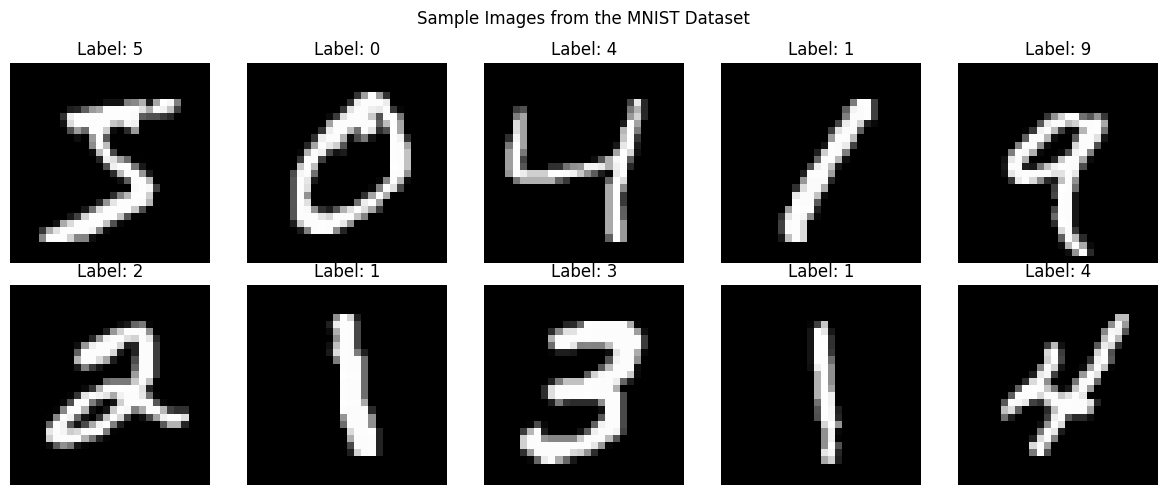

In [4]:

# Display 10 sample images with their labels
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    
    # Reverse normalization for display
    image = image * 0.3081 + 0.1307
    
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("Sample Images from the MNIST Dataset")
plt.tight_layout()
plt.show()


In [5]:

class BasicCNN(nn.Module):
    def __init__(self, activation_name="ReLU"):
        super(BasicCNN, self).__init__()

        # Convolutional layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Select activation function
        if activation_name == "ReLU":
            self.activation = nn.ReLU()
        elif activation_name == "Leaky ReLU":
            self.activation = nn.LeakyReLU(negative_slope=0.01)
        elif activation_name == "ELU":
            self.activation = nn.ELU(alpha=1.0)
        elif activation_name == "GELU":
            self.activation = nn.GELU()
        else:
            raise ValueError(f"Unknown activation function: {activation_name}")

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.activation(self.conv1(x)))
        x = self.pool(self.activation(self.conv2(x)))

        x = torch.flatten(x, start_dim=1)

        x = self.activation(self.fc1(x))
        x = self.fc2(x)

        return x


# Test the model with a sample batch
model = BasicCNN(activation_name="ReLU")
sample_images, sample_labels = next(iter(train_loader))
sample_outputs = model(sample_images)

print("Model created successfully.")
print("Input batch shape:", sample_images.shape)
print("Output shape:", sample_outputs.shape)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Model created successfully.
Input batch shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
Trainable parameters: 421642


In [6]:

def train_model(model, train_loader, criterion, optimizer, epochs=5):
    history = {
        "train_loss": [],
        "train_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_accuracy = 100.0 * correct / total

        history["train_loss"].append(epoch_loss)
        history["train_accuracy"].append(epoch_accuracy)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} | "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    training_time = time.time() - start_time

    return history, training_time


def evaluate_model(model, test_loader):
    model.eval()
    all_predictions = []
    all_labels = []
    total_loss = 0.0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    average_loss = total_loss / len(test_loader.dataset)

    metrics = {
        "test_loss": average_loss,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "f1_score": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        )
    }

    return metrics, all_labels, all_predictions


In [7]:

# Experiment configuration
ACTIVATIONS = ["ReLU", "Leaky ReLU", "ELU", "GELU"]

EPOCHS = 5
LEARNING_RATE = 0.001
BATCH_SIZE = 64
SEED = 42

# Loss function
criterion = nn.CrossEntropyLoss()

# Create a reproducible training loader
def make_train_loader():
    generator = torch.Generator()
    generator.manual_seed(SEED)

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

# Verify configuration
print("Activation functions:", ACTIVATIONS)
print("Epochs per model:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Optimizer: Adam")
print("Loss function: CrossEntropyLoss")
print("Training samples per model:", len(train_dataset))
print("Testing samples per model:", len(test_dataset))


Activation functions: ['ReLU', 'Leaky ReLU', 'ELU', 'GELU']
Epochs per model: 5
Learning rate: 0.001
Batch size: 64
Optimizer: Adam
Loss function: CrossEntropyLoss
Training samples per model: 60000
Testing samples per model: 10000


In [8]:

results = []
histories = {}
trained_models = {}
predictions_store = {}

for activation_name in ACTIVATIONS:
    print(f"\n{'=' * 50}")
    print(f"Training CNN with {activation_name}")
    print("=" * 50)

    # Reset the seed so each model starts from a reproducible setup
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    model = BasicCNN(activation_name=activation_name)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()

    train_loader_exp = make_train_loader()

    history, training_time = train_model(
        model,
        train_loader_exp,
        criterion,
        optimizer,
        epochs=EPOCHS
    )

    metrics, y_true, y_pred = evaluate_model(model, test_loader)

    result = {
        "Activation": activation_name,
        "Training Time (s)": training_time,
        "Test Loss": metrics["test_loss"],
        "Accuracy (%)": metrics["accuracy"] * 100,
        "Precision (%)": metrics["precision"] * 100,
        "Recall (%)": metrics["recall"] * 100,
        "F1 Score (%)": metrics["f1_score"] * 100
    }

    results.append(result)
    histories[activation_name] = history
    trained_models[activation_name] = model
    predictions_store[activation_name] = {
        "true": y_true,
        "predicted": y_pred
    }

    print(f"\n{activation_name} evaluation:")
    for metric, value in result.items():
        if metric != "Activation":
            print(f"{metric}: {value:.4f}")

results_df = pd.DataFrame(results)

print("\nFinal comparison:")
display(results_df.round(4))



Training CNN with ReLU
Epoch [1/5] Loss: 0.1378 | Accuracy: 95.73%
Epoch [2/5] Loss: 0.0429 | Accuracy: 98.68%
Epoch [3/5] Loss: 0.0293 | Accuracy: 99.08%
Epoch [4/5] Loss: 0.0218 | Accuracy: 99.31%
Epoch [5/5] Loss: 0.0173 | Accuracy: 99.42%

ReLU evaluation:
Training Time (s): 547.4859
Test Loss: 0.0352
Accuracy (%): 99.0200
Precision (%): 99.0447
Recall (%): 98.9862
F1 Score (%): 99.0098

Training CNN with Leaky ReLU
Epoch [1/5] Loss: 0.1296 | Accuracy: 95.96%
Epoch [2/5] Loss: 0.0397 | Accuracy: 98.81%
Epoch [3/5] Loss: 0.0266 | Accuracy: 99.14%
Epoch [4/5] Loss: 0.0200 | Accuracy: 99.34%
Epoch [5/5] Loss: 0.0151 | Accuracy: 99.47%

Leaky ReLU evaluation:
Training Time (s): 635.8139
Test Loss: 0.0325
Accuracy (%): 98.9800
Precision (%): 98.9939
Recall (%): 98.9299
F1 Score (%): 98.9558

Training CNN with ELU
Epoch [1/5] Loss: 0.1163 | Accuracy: 96.39%
Epoch [2/5] Loss: 0.0372 | Accuracy: 98.85%
Epoch [3/5] Loss: 0.0261 | Accuracy: 99.14%
Epoch [4/5] Loss: 0.0188 | Accuracy: 99.40%

,Activation,Training Time (s),Test Loss,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,ReLU,547.4859,0.0352,99.02,99.0447,98.9862,99.0098
1,Leaky ReLU,635.8139,0.0325,98.98,98.9939,98.9299,98.9558
2,ELU,764.9527,0.0507,98.70,98.7114,98.6534,98.6752
3,GELU,765.0680,0.0276,99.10,99.1058,99.0701,99.0853


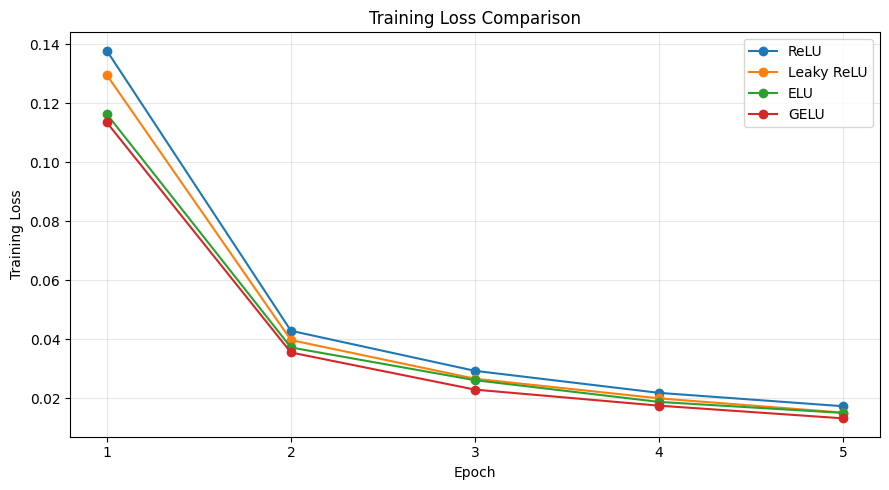

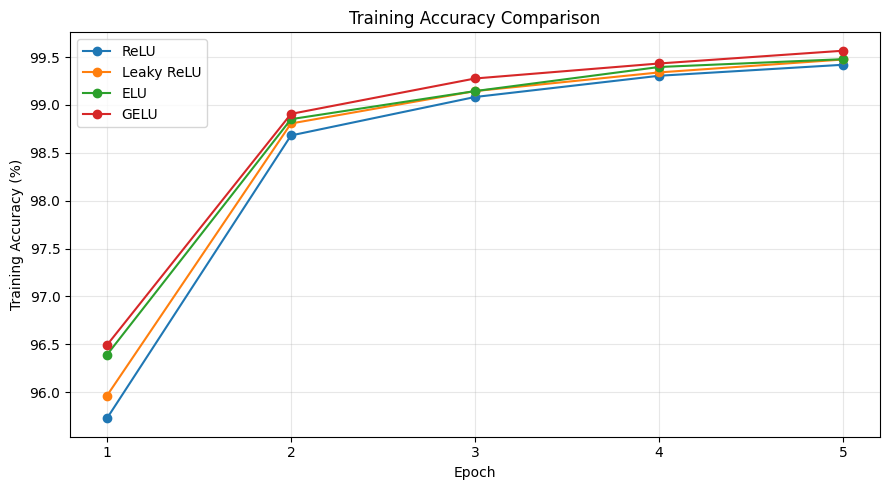

In [9]:

epochs_range = range(1, EPOCHS + 1)

# Training loss comparison
plt.figure(figsize=(9, 5))

for activation_name in ACTIVATIONS:
    plt.plot(
        epochs_range,
        histories[activation_name]["train_loss"],
        marker="o",
        label=activation_name
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("training_loss_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# Training accuracy comparison
plt.figure(figsize=(9, 5))

for activation_name in ACTIVATIONS:
    plt.plot(
        epochs_range,
        histories[activation_name]["train_accuracy"],
        marker="o",
        label=activation_name
    )

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("training_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


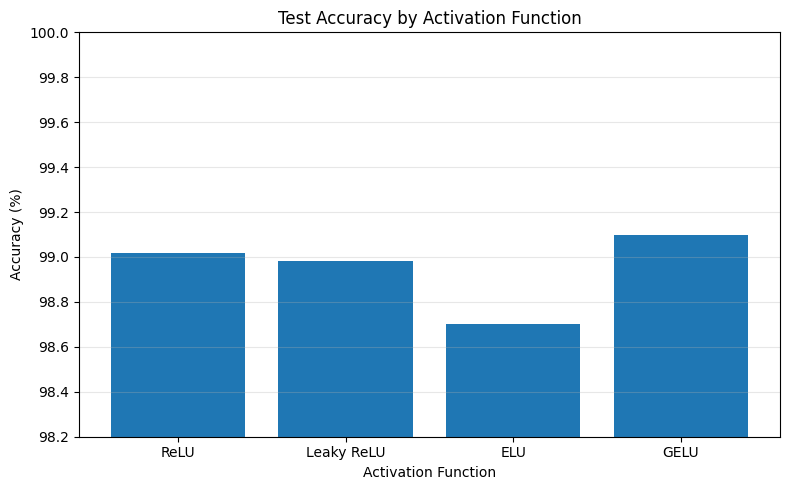

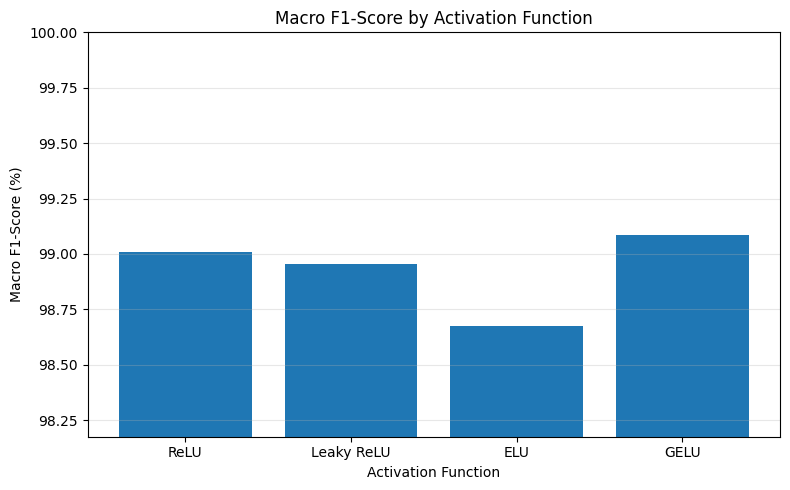

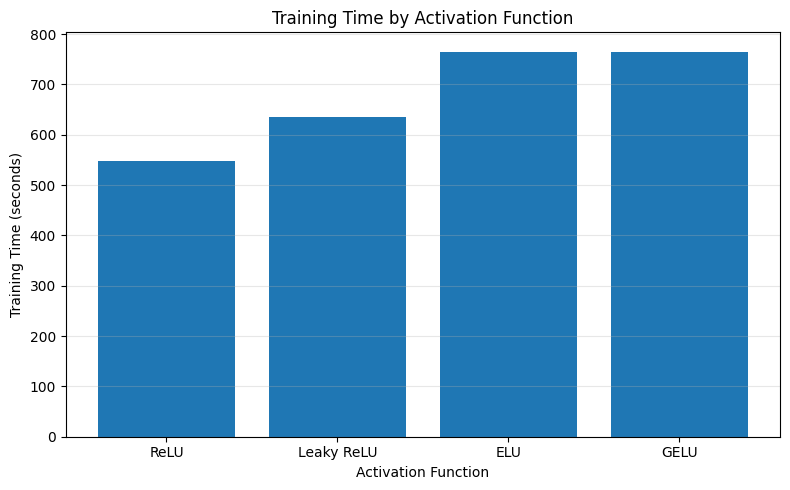

In [10]:

# Plot 1: Test accuracy
plt.figure(figsize=(8, 5))
plt.bar(results_df["Activation"], results_df["Accuracy (%)"])
plt.title("Test Accuracy by Activation Function")
plt.xlabel("Activation Function")
plt.ylabel("Accuracy (%)")
plt.ylim(
    max(0, results_df["Accuracy (%)"].min() - 0.5),
    100
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("test_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# Plot 2: Macro F1-score
plt.figure(figsize=(8, 5))
plt.bar(results_df["Activation"], results_df["F1 Score (%)"])
plt.title("Macro F1-Score by Activation Function")
plt.xlabel("Activation Function")
plt.ylabel("Macro F1-Score (%)")
plt.ylim(
    max(0, results_df["F1 Score (%)"].min() - 0.5),
    100
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("f1_score_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# Plot 3: Training time
plt.figure(figsize=(8, 5))
plt.bar(results_df["Activation"], results_df["Training Time (s)"])
plt.title("Training Time by Activation Function")
plt.xlabel("Activation Function")
plt.ylabel("Training Time (seconds)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("training_time_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


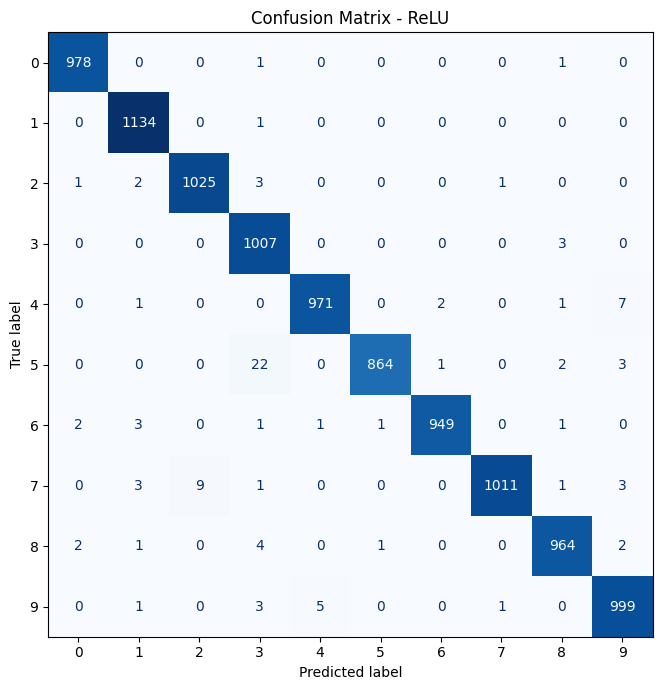

Saved: relu_confusion_matrix.png


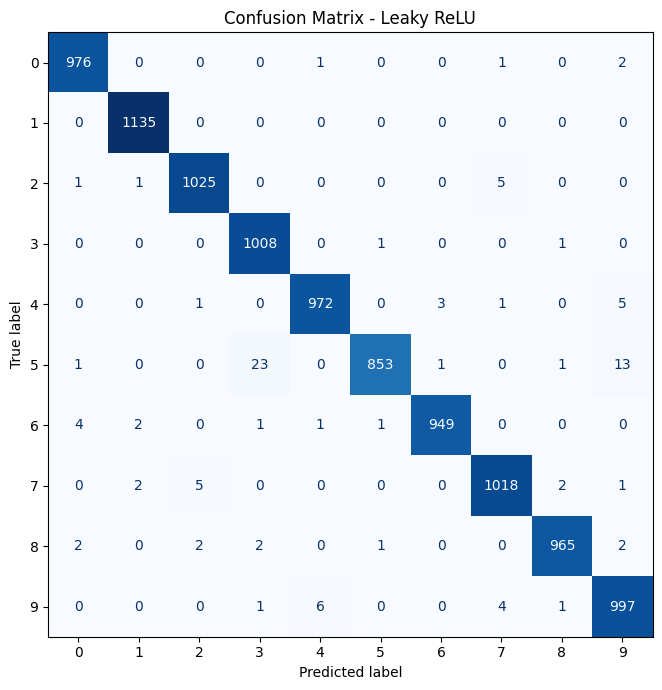

Saved: leaky_relu_confusion_matrix.png


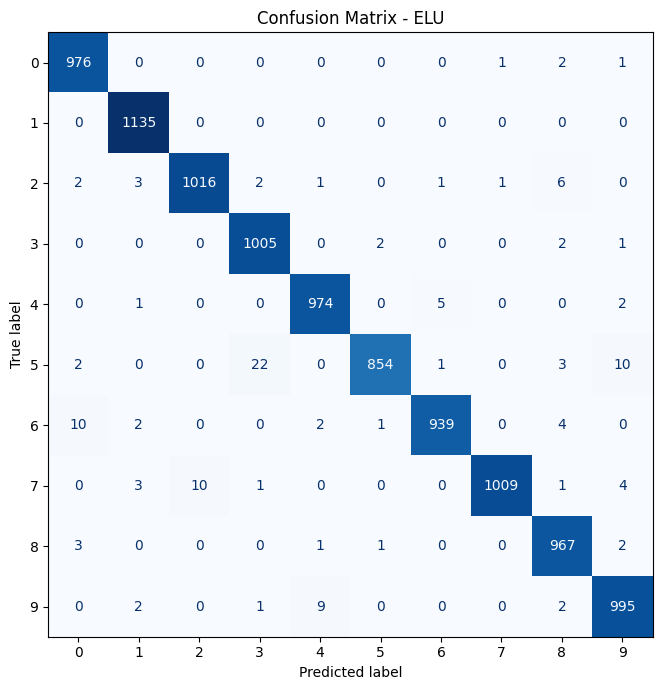

Saved: elu_confusion_matrix.png


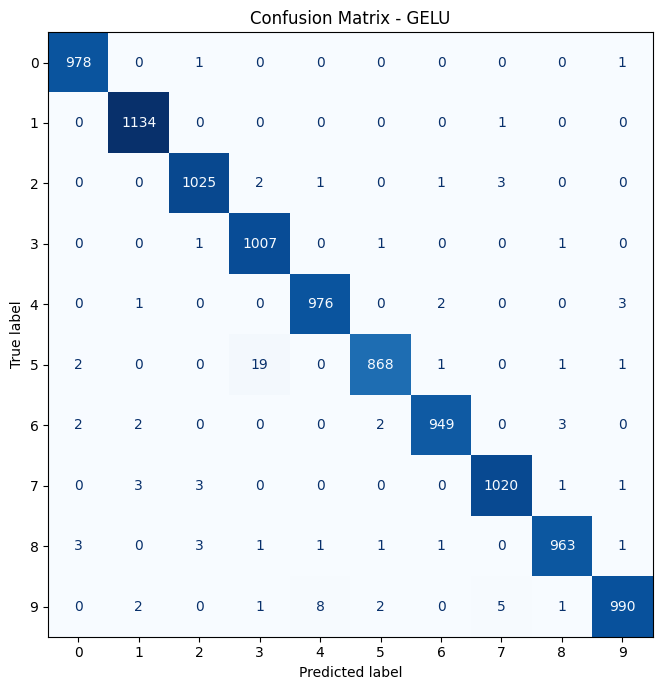

Saved: gelu_confusion_matrix.png


In [11]:

for activation_name in ACTIVATIONS:
    y_true = predictions_store[activation_name]["true"]
    y_pred = predictions_store[activation_name]["predicted"]

    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(8, 7))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(range(10))
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(f"Confusion Matrix - {activation_name}")
    plt.tight_layout()

    filename = (
        activation_name.lower()
        .replace(" ", "_")
        .replace("-", "")
        + "_confusion_matrix.png"
    )

    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {filename}")


In [12]:

# Export the overall comparison table
results_df.to_csv("activation_function_results.csv", index=False)

# Export detailed predictions for all test images
prediction_rows = []

for activation_name in ACTIVATIONS:
    y_true = predictions_store[activation_name]["true"]
    y_pred = predictions_store[activation_name]["predicted"]

    for i, (actual, predicted) in enumerate(zip(y_true, y_pred)):
        prediction_rows.append({
            "Activation": activation_name,
            "Image_Index": i,
            "Actual_Label": actual,
            "Predicted_Label": predicted,
            "Correct": actual == predicted
        })

predictions_df = pd.DataFrame(prediction_rows)
predictions_df.to_csv("activation_function_predictions.csv", index=False)

# Display and verify the saved results
print("Comparison results saved.")
print("Prediction details saved.")
print("Comparison rows:", len(results_df))
print("Prediction rows:", len(predictions_df))

display(results_df.round(4))
display(predictions_df.head(10))


Comparison results saved.
Prediction details saved.
Comparison rows: 4
Prediction rows: 40000


,Activation,Training Time (s),Test Loss,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,ReLU,547.4859,0.0352,99.02,99.0447,98.9862,99.0098
1,Leaky ReLU,635.8139,0.0325,98.98,98.9939,98.9299,98.9558
2,ELU,764.9527,0.0507,98.70,98.7114,98.6534,98.6752
3,GELU,765.0680,0.0276,99.10,99.1058,99.0701,99.0853


,Activation,Image_Index,Actual_Label,Predicted_Label,Correct
0,ReLU,0,7,7,True
1,ReLU,1,2,2,True
2,ReLU,2,1,1,True
3,ReLU,3,0,0,True
4,ReLU,4,4,4,True
5,ReLU,5,1,1,True
6,ReLU,6,4,4,True
7,ReLU,7,9,9,True
8,ReLU,8,5,5,True
9,ReLU,9,9,9,True
